# Gamatechno AI Support Copilot — Multi-Task Ticket Triage (IndoBERT PEFT/LoRA + Focal Loss + OOF Calibration)

**Target Posisi & Instansi:** AI untuk Customer/Technical Support — PT Gamatechno Indonesia  
**Arsitektur:**
1. **Shared Backbone:** `indobenchmark/indobert-base-p1` (Frozen Base Parameters + **PEFT/LoRA** `r=16, lora_alpha=32, lora_dropout=0.10` pada modul `["query", "key", "value", "dense"]`).
2. **Dual Classification Heads (768 → 256 → 4):**
   - `CategoryHead`: Cross-Entropy Loss dengan `label_smoothing = 0.05` (`Hardware_POS`, `Billing_Payment`, `Academic_Portal`, `Warranty_Claim`).
   - `UrgencyHead`: Multi-Class Focal Loss ($\gamma = 2.0$, bobot terbalik frekuensi kelas $\alpha_t$ dari `train_tickets.csv`) (`Low`, `Medium`, `High`, `Critical`).
3. **Out-of-Fold (OOF) Calibration:** Temperature Scaling $T$ & optimasi ambang batas $\theta_{\text{crit}}^* \in [0.20, 0.60]$ untuk memaksimalkan $F_{\beta=1.5}$ pada kelas `Critical`.

In [1]:
# 1. Setup Environment & Clone Repository (Otomatis menyesuaikan jika dijalankan di Google Colab)
import os
from pathlib import Path

if not Path("configs/config.yaml").exists():
    if not Path("customerServiceTicketRAG").exists():
        !git clone https://github.com/TheGasz/customerServiceTicketRAG.git
    os.chdir("customerServiceTicketRAG")

!pip install -q peft transformers accelerate lightgbm scikit-learn pandas pyyaml matplotlib seaborn

import torch
print("Working Directory:", Path.cwd())
print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU Device:", torch.cuda.get_device_name(0))

Cloning into 'customerServiceTicketRAG'...
remote: Enumerating objects: 50, done.
remote: Counting objects: 100% (50/50), done.
remote: Compressing objects: 100% (44/44), done.
remote: Total 50 (delta 4), reused 50 (delta 4), pack-reused 0 (from 0)
Receiving objects: 100% (50/50), 208.38 KiB | 5.21 MiB/s, done.
Resolving deltas: 100% (4/4), done.
Working Directory: /content/customerServiceTicketRAG
PyTorch Version: 2.11.0+cu130
CUDA Available: True
GPU Device: Tesla T4


In [2]:
# 2. Verifikasi Dataset Tiket & Audit Zero Data Leakage (GroupShuffleSplit by user_id)
import pandas as pd
from src.preprocessing.splitter import verify_zero_user_leakage

train_df = pd.read_csv("data/tickets/train_tickets.csv")
val_df = pd.read_csv("data/tickets/val_tickets.csv")
test_df = pd.read_csv("data/tickets/test_tickets.csv")

verify_zero_user_leakage(train_df, val_df, test_df, user_col="user_id")
print(f"Zero Data Leakage Verified! Train={len(train_df)} ({train_df['user_id'].nunique()} users), "
      f"Val={len(val_df)} ({val_df['user_id'].nunique()} users), "
      f"Test={len(test_df)} ({test_df['user_id'].nunique()} users)")

display(pd.DataFrame({
    "Train Category": train_df["category"].value_counts(),
    "Val Category": val_df["category"].value_counts(),
    "Test Category": test_df["category"].value_counts(),
}))

display(pd.DataFrame({
    "Train Urgency": train_df["urgency"].value_counts(),
    "Val Urgency": val_df["urgency"].value_counts(),
    "Test Urgency": test_df["urgency"].value_counts(),
}))

Zero Data Leakage Verified! Train=840 (168 users), Val=180 (36 users), Test=180 (36 users)


,Train Category,Val Category,Test Category
category,,,
Academic_Portal,117,15,18
Billing_Payment,207,51,42
Hardware_POS,282,71,97
Warranty_Claim,234,43,23


,Train Urgency,Val Urgency,Test Urgency
urgency,,,
Medium,356,87,66
Low,222,41,46
High,147,32,40
Critical,115,20,28


In [3]:
# 3. Pelatihan & Evaluasi Baseline (TF-IDF + LightGBM di dalam sklearn.pipeline.Pipeline)
from src.triage.baseline_tfidf import train_and_evaluate_baseline

baseline_results = train_and_evaluate_baseline("configs/config.yaml")
baseline_summary = {
    k: v for k, v in baseline_results["test"].items() if not isinstance(v, list)
}
print("=== BASELINE TF-IDF + LIGHTGBM (TEST SPLIT) ===")
display(pd.DataFrame([baseline_summary]))

=== BASELINE TF-IDF + LIGHTGBM (TEST SPLIT) ===


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,category_macro_f1,urgency_macro_f1,critical_pr_auc,critical_precision,critical_recall,critical_f1
0,0.7713,0.6259,0.6745,0.8824,0.5357,0.6667


In [5]:
!pip install -q -U "torchao>=0.16.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 64.0 MB/s eta 0:00:00


[train_triage] Using device: cuda


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[train_triage] Parameter Summary: {'total_params': 127520008, 'trainable_params': 3078664, 'trainable_percentage': 2.4143}
[Epoch 1/8] {'epoch': 1, 'train_loss': 1.6205, 'val_category_macro_f1': 0.8438, 'val_urgency_macro_f1': 0.5778, 'elapsed_sec': 17.89}
[Epoch 2/8] {'epoch': 2, 'train_loss': 0.2974, 'val_category_macro_f1': 0.9875, 'val_urgency_macro_f1': 0.7932, 'elapsed_sec': 17.38}
[Epoch 3/8] {'epoch': 3, 'train_loss': 0.2162, 'val_category_macro_f1': 0.9958, 'val_urgency_macro_f1': 0.9495, 'elapsed_sec': 17.52}
[Epoch 4/8] {'epoch': 4, 'train_loss': 0.2057, 'val_category_macro_f1': 0.9916, 'val_urgency_macro_f1': 0.956, 'elapsed_sec': 18.23}
[Epoch 5/8] {'epoch': 5, 'train_loss': 0.2042, 'val_category_macro_f1': 0.9916, 'val_urgency_macro_f1': 0.956, 'elapsed_sec': 19.09}
[Epoch 6/8] {'epoch': 6, 'train_loss': 0.2039, 'val_category_macro_f1': 0.9916, 'val_urgency_macro_f1': 0.9509, 'elapsed_sec': 20.2}
[Epoch 7/8] {'epoch': 7, 'train_loss': 0.204, 'val_category_macro_f1': 0.991

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[train_triage] Saved calibrated OOF threshold to models/oof_thresholds.json: {'temperature': 0.6, 'critical_threshold': 0.495, 'val_critical_fbeta_1_5': 0.9848, 'val_critical_precision': 0.9524, 'val_critical_recall': 1.0, 'parameter_summary': {'total_params': 127520008, 'trainable_params': 3078664, 'trainable_percentage': 2.4143}, 'training_history': [{'epoch': 1, 'train_loss': 1.6205, 'val_category_macro_f1': 0.8438, 'val_urgency_macro_f1': 0.5778, 'elapsed_sec': 17.89}, {'epoch': 2, 'train_loss': 0.2974, 'val_category_macro_f1': 0.9875, 'val_urgency_macro_f1': 0.7932, 'elapsed_sec': 17.38}, {'epoch': 3, 'train_loss': 0.2162, 'val_category_macro_f1': 0.9958, 'val_urgency_macro_f1': 0.9495, 'elapsed_sec': 17.52}, {'epoch': 4, 'train_loss': 0.2057, 'val_category_macro_f1': 0.9916, 'val_urgency_macro_f1': 0.956, 'elapsed_sec': 18.23}, {'epoch': 5, 'train_loss': 0.2042, 'val_category_macro_f1': 0.9916, 'val_urgency_macro_f1': 0.956, 'elapsed_sec': 19.09}, {'epoch': 6, 'train_loss': 0.203

,epoch,train_loss,val_category_macro_f1,val_urgency_macro_f1,elapsed_sec
0,1,1.6205,0.8438,0.5778,17.89
1,2,0.2974,0.9875,0.7932,17.38
2,3,0.2162,0.9958,0.9495,17.52
3,4,0.2057,0.9916,0.9560,18.23
4,5,0.2042,0.9916,0.9560,19.09
5,6,0.2039,0.9916,0.9509,20.20
6,7,0.2040,0.9916,0.9533,20.28
7,8,0.2038,0.9916,0.9533,19.61


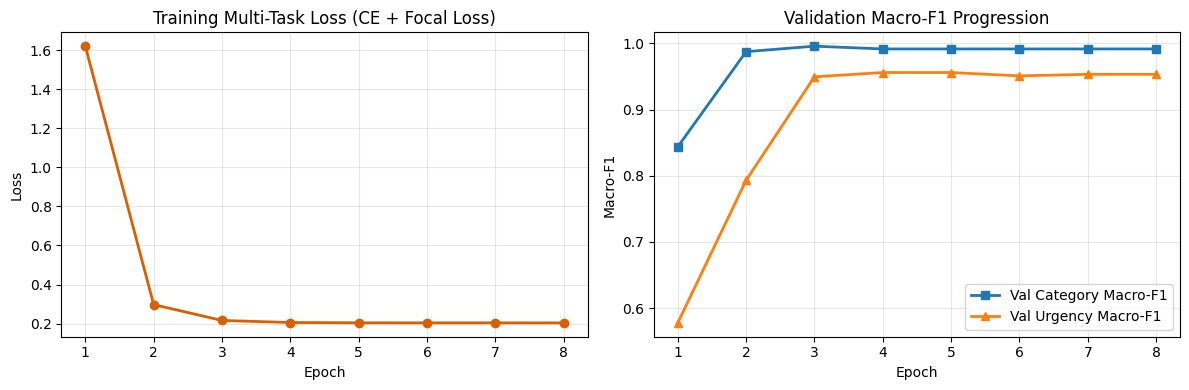

In [6]:
# 4. Fine-Tuning Multi-Task IndoBERT + PEFT/LoRA + Focal Loss & OOF Threshold Calibration
import matplotlib.pyplot as plt
from src.triage.train_triage import train_indobert_lora

calib_and_history = train_indobert_lora(config_path="configs/config.yaml")

print("\n=== RINGKASAN PARAMETER & KALIBRASI OOF ===")
print("Parameter Summary:", calib_and_history["parameter_summary"])
print(f"Optimal Temperature (T): {calib_and_history['temperature']}")
print(f"Optimal Critical Threshold (theta_crit*): {calib_and_history['critical_threshold']}")
print(f"Val Critical F_beta=1.5: {calib_and_history['val_critical_fbeta_1_5']} "
      f"(Precision={calib_and_history['val_critical_precision']}, Recall={calib_and_history['val_critical_recall']})")

# Visualisasi kurva pelatihan per Epoch
hist_df = pd.DataFrame(calib_and_history["training_history"])
display(hist_df)

fig, ax1 = plt.subplots(1, 2, figsize=(12, 4))
ax1[0].plot(hist_df["epoch"], hist_df["train_loss"], marker="o", linewidth=2, color="#d95f02")
ax1[0].set_title("Training Multi-Task Loss (CE + Focal Loss)")
ax1[0].set_xlabel("Epoch")
ax1[0].set_ylabel("Loss")
ax1[0].grid(True, alpha=0.3)

ax1[1].plot(hist_df["epoch"], hist_df["val_category_macro_f1"], marker="s", label="Val Category Macro-F1", linewidth=2)
ax1[1].plot(hist_df["epoch"], hist_df["val_urgency_macro_f1"], marker="^", label="Val Urgency Macro-F1", linewidth=2)
ax1[1].set_title("Validation Macro-F1 Progression")
ax1[1].set_xlabel("Epoch")
ax1[1].set_ylabel("Macro-F1")
ax1[1].legend()
ax1[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

=== 1. PERBANDINGAN MODEL PADA HELD-OUT TEST SPLIT ===


,category_macro_f1,urgency_macro_f1,critical_pr_auc,critical_precision,critical_recall,critical_f1
baseline_tfidf_lightgbm,0.7713,0.6259,0.6745,0.8824,0.5357,0.6667
indobert_lora_argmax,0.9818,0.9644,1.0000,0.9655,1.0000,0.9825
indobert_lora_oof_calibrated,0.9818,0.9644,1.0000,0.9655,1.0000,0.9825



NER Exact-Match F1: 1.0 (Target >= 0.95)
Formal vs Slang/Typo Gap: 2.34% (Target <= 8.0%)

=== 2. SLICING ERROR ANALYSIS PER SEGMEN TIKET ===


,sample_count,baseline_macro_f1,indobert_lora_macro_f1,delta_improvement
Tiket Formal (>15 Kata),123.0,0.6912,0.9781,0.2869
Tiket Pendek (<12 Kata),27.0,0.7779,0.9500,0.1721
Tiket Slang/Typo,57.0,0.6979,0.9547,0.2568
Tiket Dengan Kode Error Eksplisit,115.0,0.7023,0.9721,0.2698
Tiket Tanpa Kode Error,65.0,0.6861,0.9756,0.2895
Tiket Keluhan Multi-Masalah,12.0,0.5691,0.9571,0.3880



=== 3. TOP-10 PREDIKSI SALAH TERBURUK (TOP-LOSS ERRORS) ===


,ticket_id,sanitized_message,true_category,pred_category,true_urgency,pred_urgency,loss
0,TCK-00865,"Yth. Tim Dukungan Operasional Gamatechno, ceta...",Hardware_POS,Hardware_POS,Medium,Critical,2.6480
1,TCK-00425,"Yth. Tim Dukungan Operasional Gamatechno, kega...",Academic_Portal,Academic_Portal,Medium,High,1.0891
2,TCK-00076,"Yth. Tim Dukungan Operasional Gamatechno, moho...",Hardware_POS,Hardware_POS,Medium,Low,1.0374
3,TCK-00523,"Salam sejahtera, bersama tiket ini unit operas...",Billing_Payment,Billing_Payment,Medium,Low,0.8954
4,TCK-00423,"halo gan tolong dibantu segera, pelanggan meng...",Warranty_Claim,Warranty_Claim,Medium,High,0.8846
5,TCK-00631,"Halo Tim Care Gamatechno, mohon penanganan unt...",Warranty_Claim,Warranty_Claim,Medium,High,0.8311
6,TCK-00091,Selamat siang Layanan Pelanggan & Teknisi Gama...,Billing_Payment,Billing_Payment,Medium,Medium,0.8110
7,TCK-01047,"halo gan tolong dibantu segera, tiket klaim pe...",Warranty_Claim,Warranty_Claim,Medium,High,0.7966
8,TCK-00927,"halo gan tolong dibantu segera, unit pelacak k...",Hardware_POS,Hardware_POS,High,High,0.6487
9,TCK-01145,"Yth. Tim Dukungan Operasional Gamatechno, gate...",Academic_Portal,Academic_Portal,Medium,Medium,0.6209



=== 4. VISUALISASI CONFUSION MATRIX ===


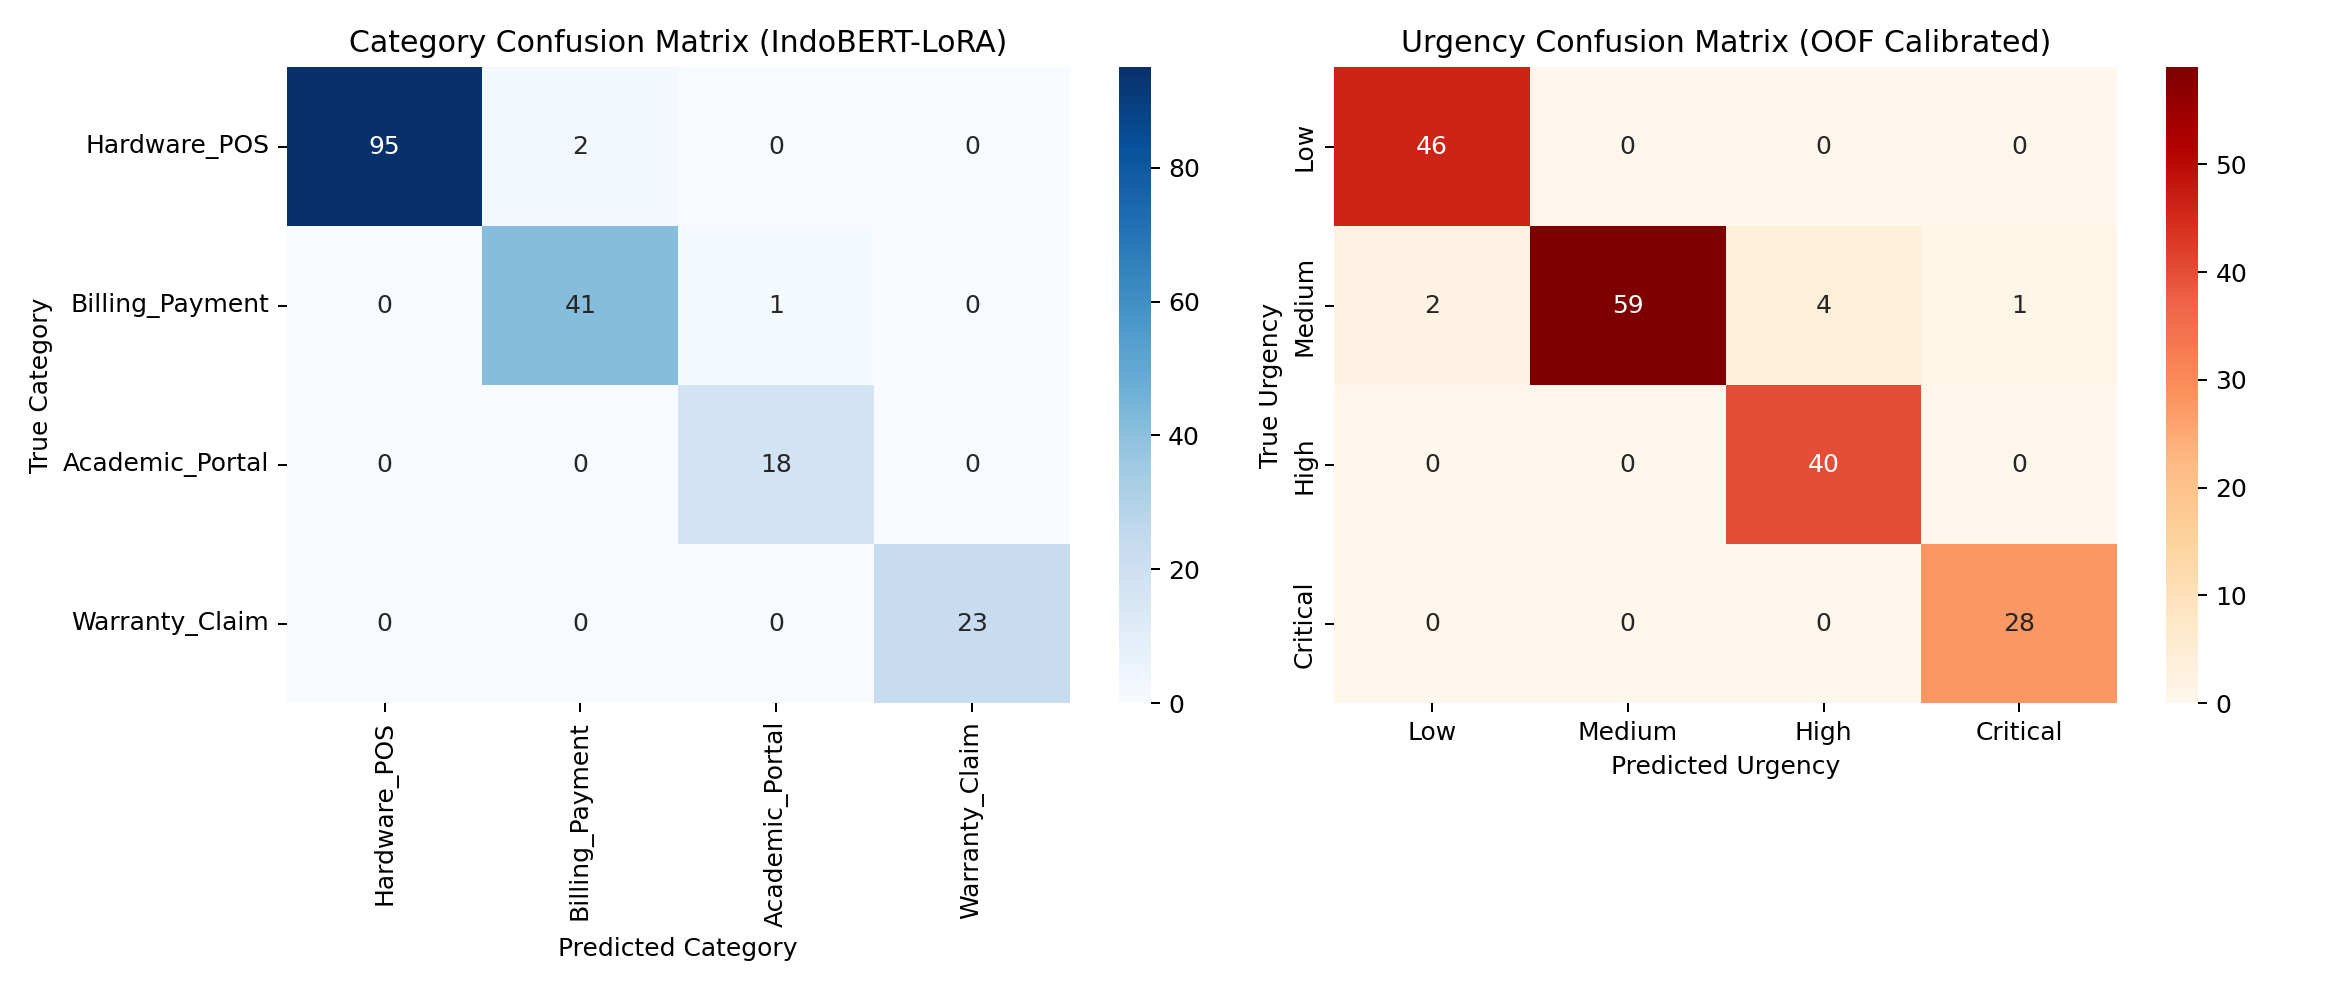

In [7]:
# 5. Evaluasi Komprehensif pada Test Split, Slicing Error Analysis & Confusion Matrix
from IPython.display import Image, display
from src.triage.evaluate_triage import evaluate_all_triage_models

eval_report = evaluate_all_triage_models("configs/config.yaml")

print("=== 1. PERBANDINGAN MODEL PADA HELD-OUT TEST SPLIT ===")
models_df = pd.DataFrame(eval_report["models"]).T
display(models_df)

print(f"\nNER Exact-Match F1: {eval_report['entity_exact_match_f1']} (Target >= 0.95)")
print(f"Formal vs Slang/Typo Gap: {eval_report['formal_vs_slang_gap'] * 100:.2f}% (Target <= 8.0%)")

print("\n=== 2. SLICING ERROR ANALYSIS PER SEGMEN TIKET ===")
slicing_df = pd.DataFrame(eval_report["slicing_analysis"]).T
slicing_df["delta_improvement"] = (
    slicing_df["indobert_lora_macro_f1"] - slicing_df["baseline_macro_f1"]
).round(4)
display(slicing_df)

print("\n=== 3. TOP-10 PREDIKSI SALAH TERBURUK (TOP-LOSS ERRORS) ===")
display(pd.DataFrame(eval_report["top_10_worst_predictions"]))

print("\n=== 4. VISUALISASI CONFUSION MATRIX ===")
display(Image(filename="reports/confusion_matrix_triage.png"))

In [8]:
# 6. Bungkus Seluruh Artefak Model & Laporan Evaluasi ke ZIP untuk Diunduh
import zipfile
from pathlib import Path

artifact_zip = Path("trained_indobert_lora_artifacts.zip")
paths_to_pack = [
    Path("models/indobert_lora"),
    Path("models/oof_thresholds.json"),
    Path("models/baseline_tfidf_lgbm.joblib"),
    Path("reports/triage_benchmark.json"),
    Path("reports/confusion_matrix_triage.png"),
    Path("reports/triage_slicing_report.md"),
]

with zipfile.ZipFile(artifact_zip, "w", zipfile.ZIP_DEFLATED) as zf:
    for item in paths_to_pack:
        if item.is_dir():
            for sub in item.rglob("*"):
                if sub.is_file():
                    zf.write(sub, sub.as_posix())
        elif item.is_file():
            zf.write(item, item.as_posix())

print(f"Berhasil membungkus seluruh artefak ke: {artifact_zip.resolve()} ({artifact_zip.stat().st_size / 1e6:.2f} MB)")

try:
    from google.colab import files
    files.download(str(artifact_zip))
except ImportError:
    print("Berjalan di luar Google Colab; file zip tersimpan di direktori kerja.")

Berhasil membungkus seluruh artefak ke: /content/customerServiceTicketRAG/trained_indobert_lora_artifacts.zip (11.75 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>